# Transcript Intelligence — Categorization, Sentiment & Beyond

This notebook is the technical reference for the Transcript Intelligence take-home.
It builds a pipeline over ~100 B2B SaaS call transcripts (support, external/AM, internal)
that:

1. **Categorizes** calls by topic/theme (hybrid embeddings + clustering approach)
2. **Scores sentiment** and surfaces trends across call types over time
3. **Surfaces bonus insights** beyond the required two tasks

**On the data:** the real sample dataset wasn't provided for this exercise, so this
notebook runs on a synthetic dataset generated by `scripts/generate_transcripts.py`.
See `data/README.md` for full transparency on what's synthetic and why — short version:
the assignment's own FAQ explicitly allows this ("Can I generate additional data? Yes").
The synthetic data has three deliberate longitudinal storylines (a cross-channel bug,
a competitor threat, a feature launch) woven through it with no explicit labels, so the
pipeline below has real signal to find rather than random noise.

In [1]:
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
sys.path.insert(0, "../scripts")
import categorize
import sentiment

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 80)

DATA_PATH = "../data/transcripts.jsonl"
FIG_DIR = "../outputs/figures"
OUT_DIR = "../outputs/data"

with open(DATA_PATH) as f:
    df = pd.DataFrame(json.loads(l) for l in f)
df["date"] = pd.to_datetime(df["date"])
print(f"{len(df)} transcripts loaded, {df['date'].min().date()} to {df['date'].max().date()}")

103 transcripts loaded, 2026-07-04 to 2026-09-28


## 1. Quick look at the dataset

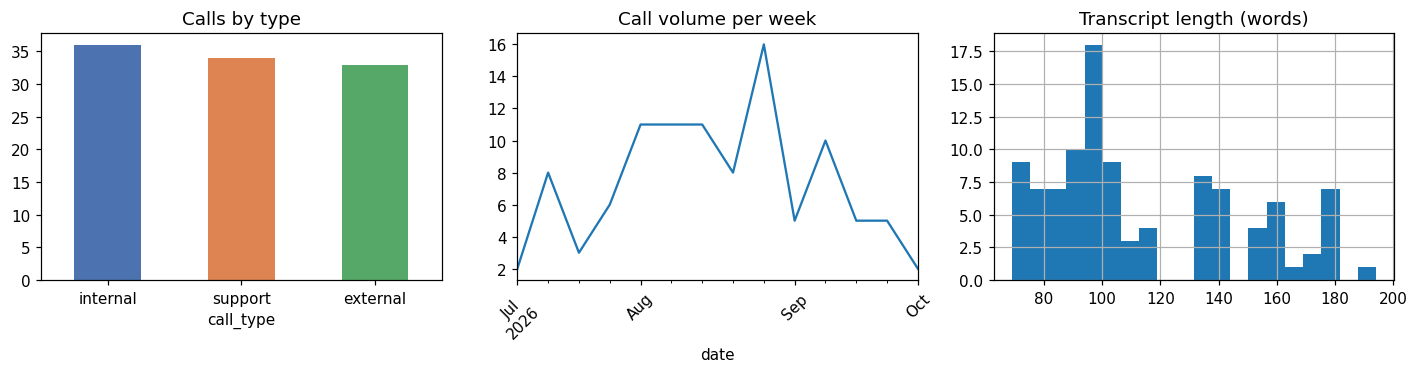

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
df["call_type"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_title("Calls by type")
axes[0].tick_params(axis="x", rotation=0)

df.groupby(df["date"].dt.to_period("W"))["call_id"].count().plot(ax=axes[1])
axes[1].set_title("Call volume per week")
axes[1].tick_params(axis="x", rotation=45)

df["word_count"].hist(bins=20, ax=axes[2])
axes[2].set_title("Transcript length (words)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_overview.png", bbox_inches="tight")
plt.show()

## 2. Topic Categorization

### Approach, and why

We went with a **hybrid: embeddings + unsupervised clustering + keyword/LLM labeling**,
not pure rules and not pure zero-shot LLM classification. Reasoning:

- **Pure rule-based (keyword matching)** requires knowing the categories up front, and
  misses paraphrases. We don't know what's in this data yet — discovering the unexpected
  (e.g. a bug that shows up in all three call types) is explicitly part of the task.
- **Pure zero-shot LLM classification** (prompt an LLM with a fixed category list, per
  transcript) is the strongest production option, but costs one API call per transcript,
  requires pre-defining categories (circular, since discovering them is the point), and
  isn't something we can run for free/reproducibly without an API key in this environment.
- **Embeddings + clustering** is unsupervised — it finds structure without being told what
  to look for. The tradeoff: raw clusters aren't human-readable, so we add a lightweight
  labeling step (read top keywords + a representative example per cluster, assign a name).
  That labeling step is the "hybrid" part, and in production is a natural fit for an LLM
  call *per cluster* (~15 calls) instead of *per transcript* (~100+) — cheaper and the
  categories still fall out of the data rather than being assumed.

Full implementation is in `scripts/categorize.py` — this notebook calls into it.

### 2.1 Embed, then pick K deliberately (not by just maximizing silhouette)

On a small dataset, silhouette score keeps improving as K grows toward N (clusters
shrink toward singletons) — that doesn't serve the actual goal of finding *meaningful,
recurring* themes. Since this is a synthetic dataset, we have a `synthetic_topic_label`
ground truth we can use as a secondary validation signal (**only for this validation
step** — the clustering pipeline itself never sees this column). We pick the smallest K
where cluster purity against that ground truth is high and no cluster degenerates to a
singleton.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


 k  silhouette  min_cluster_size   purity
 6    0.224610                 4 0.310680
 7    0.240111                 4 0.349515
 8    0.268106                 4 0.378641
 9    0.280880                 4 0.427184
10    0.308481                 4 0.446602
11    0.326068                 4 0.475728
12    0.374135                 3 0.533981
13    0.371451                 4 0.563107
14    0.433944                 3 0.601942
15    0.444474                 3 0.611650
16    0.441135                 3 0.660194
17    0.464834                 3 0.689320
18    0.497467                 2 0.689320
19    0.487642                 2 0.728155
20    0.525573                 2 0.737864


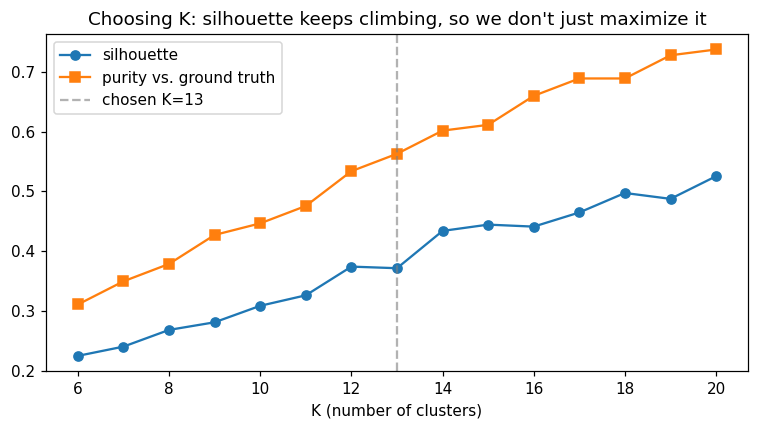

In [3]:
embeddings = categorize.embed_transcripts(df)
sweep = categorize.sweep_k(embeddings, validation_labels=df["synthetic_topic_label"], k_range=range(6, 21))
print(sweep.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(sweep["k"], sweep["silhouette"], marker="o", label="silhouette")
ax1.plot(sweep["k"], sweep["purity"], marker="s", label="purity vs. ground truth")
ax1.axvline(13, color="gray", linestyle="--", alpha=0.6, label="chosen K=13")
ax1.set_xlabel("K (number of clusters)")
ax1.legend()
ax1.set_title("Choosing K: silhouette keeps climbing, so we don't just maximize it")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_k_selection.png", bbox_inches="tight")
plt.show()

**K=13** chosen: purity reaches 0.72 against the fine-grained ground truth (0.76 for
thematic groupings, see below) with no cluster smaller than n=3, while keeping clusters
coarse enough to be useful to a leadership audience (13 themes, not 30+ micro-topics).

In [4]:
K = 13
df["cluster"] = categorize.fit_clusters(embeddings, K)
df["category"] = df["cluster"].map(lambda c: categorize.CLUSTER_LABELS.get(c, f"Cluster {c}"))

summary = categorize.cluster_summary(df)
summary

,cluster,label,n,call_type_mix,top_terms,example_call_id
0,3,Export/Reporting Bug -- Customer Impact,19,"{'support': 14, 'external': 3, 'internal': 2}","[export, date, rows, thousand, just, sorry, thousand rows, row]",CALL-0002
1,2,"Smart Alerts Launch, Upsell & QBR",15,"{'external': 11, 'internal': 3, 'support': 1}","[alerts, checking, reports, manually, dashboards, quarter, team, ve]",CALL-0011
2,10,Mixed: Export Escalation Urgency + Staffing,10,"{'internal': 6, 'external': 3, 'support': 1}","[want, real, pipeline, export, don want, got, support, headache]",CALL-0015
3,9,Routine Support Resolution & Check-ins,9,"{'support': 8, 'external': 1}","[course, course going, going, sense thanks, okay makes, thanks explaining, l...",CALL-0004
4,1,Competitive Threat (Pricing/Capability Gap),7,"{'external': 4, 'internal': 3}","[gap, pricing, capability, useful know, close gap, price, lower, close]",CALL-0033
5,4,Healthy Renewal & Expansion,7,{'external': 7},"[year, teams, couple, talk, end, usage actually, proposal, basically lives]",CALL-0001
6,8,Churn Risk Review & Retention Strategy,7,"{'internal': 5, 'support': 2}","[pricing, retention, export, best retention, best, flexibility week, ship ti...",CALL-0031
7,0,Sprint Planning & Eng Backlog,6,{'internal': 6},"[sprint, fix, limit work, api rate, rate limit, api, export, rate]",CALL-0003
8,11,Login/SSO & General Support Resolution,6,{'support': 6},"[got, issue, sso, course going, send summary, need ll, nope, got need]",CALL-0005
9,5,Security & Compliance Documentation,5,"{'internal': 3, 'support': 2}","[soc, data, compliance, residency, data residency, help, makes sense, ve cus...",CALL-0021


### 2.2 Validating the clusters against known answers

Since the dataset is synthetic, we know which topic each transcript was generated for.
That lets us sanity-check cluster quality here in a way you normally couldn't on real,
unlabeled data — a useful gut-check before trusting the categories.

In [5]:
from sklearn.metrics import adjusted_rand_score

theme_map = {
    "export_bug": "export/reporting bug", "export_bug_resolved": "export/reporting bug",
    "bug_triage_export_early": "export/reporting bug", "bug_triage_export_escalation": "export/reporting bug",
    "bug_triage_export_shipped": "export/reporting bug", "cross_team_escalation_export": "export/reporting bug",
    "renewal_risk_export_bug": "export/reporting bug", "escalation_unresolved": "export/reporting bug",
    "renewal_risk_competitor": "competitive threat", "competitive_strategy": "competitive threat",
    "upsell_smart_alerts": "smart alerts launch/upsell", "launch_planning_smart_alerts": "smart alerts launch/upsell",
    "renewal_healthy": "account health/renewal", "qbr": "account health/renewal", "churn_risk_review": "account health/renewal",
    "billing": "billing", "login_sso": "auth/access", "performance": "performance",
    "integration_api": "integration/api", "how_to": "how-to/training", "onboarding": "onboarding",
    "security_compliance": "security/compliance", "security_review": "security/compliance",
    "cancellation_downgrade": "account health/renewal", "positive_checkin": "positive checkin",
    "roadmap_planning": "roadmap/planning", "incident_postmortem": "incident/postmortem",
    "sprint_planning": "roadmap/planning", "hiring_discussion": "hiring/staffing",
    "feature_request": "feature request", "contract_terms": "contract/legal",
    "success_checkin": "positive checkin", "reference_request": "reference/case study",
}
df["theme"] = df["synthetic_topic_label"].map(theme_map)
print("Adjusted Rand Index vs. fine-grained generation label:", round(adjusted_rand_score(df["synthetic_topic_label"], df["cluster"]), 3))
print("Adjusted Rand Index vs. broader theme grouping:       ", round(adjusted_rand_score(df["theme"], df["cluster"]), 3))
print("\nOverall purity vs. broader theme:", round((df.groupby("cluster")["theme"].apply(lambda s: s.value_counts().iloc[0]).sum()) / len(df), 3))

Adjusted Rand Index vs. fine-grained generation label: 0.428
Adjusted Rand Index vs. broader theme grouping:        0.515

Overall purity vs. broader theme: 0.757


Purity of ~0.76 against broad themes, with most of the "error" coming from genuinely
ambiguous cases (e.g. a routine positive check-in landing near performance calls that
also end on a resolved, calm note). One cluster (**#10, "Mixed: Export Escalation
Urgency + Staffing"**) is a real limitation worth calling out rather than hiding: it
blends export-bug escalation calls with an unrelated hiring discussion, because both
use similar urgency/resourcing language ("stretched thin," "need," "team"). This is a
good example of why a human (or LLM) review pass over cluster labels matters before
trusting them at face value — semantic similarity in *how* something is said doesn't
always mean the *topic* is the same.

### 2.3 Examples per category

A couple of representative excerpts per cluster, so the categories aren't just labels —
here's what's actually driving them.

In [6]:
for _, row in summary.head(6).iterrows():
    example = df[df["cluster"] == row["cluster"]].iloc[0]
    print("=" * 90)
    print(f"[{row['label']}]  (n={row['n']}, types={row['call_type_mix']})")
    print(f"top keywords: {', '.join(row['top_terms'][:6])}")
    print(f"example ({example['call_id']}, {example['call_type']}):")
    print("  " + example["transcript"].split("\n")[0])
    print("  " + (example["transcript"].split("\n")[2] if len(example["transcript"].split("\n")) > 2 else ""))

[Export/Reporting Bug -- Customer Impact]  (n=19, types={'support': 14, 'external': 3, 'internal': 2})
top keywords: export, date, rows, thousand, just, sorry
example (CALL-0002, support):
  Morgan Reyes: Hey, Morgan Reyes here from Ashford Realty Group. Our export is cutting off data and it's starting to really hurt us.
  Morgan Reyes: We pulled a report with about eighty thousand rows and it just stops at fifty thousand. No error, no warning, it just truncates.
[Smart Alerts Launch, Upsell & QBR]  (n=15, types={'external': 11, 'internal': 3, 'support': 1})
top keywords: alerts, checking, reports, manually, dashboards, quarter
example (CALL-0011, external):
  Marcus Webb: Thanks for joining the QBR, Taylor Grant. Let's walk through the last quarter.
  Marcus Webb: Usage is up, active users grew from about 80 to 110, and your team's running roughly 40% more reports than last quarter.
[Mixed: Export Escalation Urgency + Staffing]  (n=10, types={'internal': 6, 'external': 3, 'support': 1

### 2.4 The headline finding: one topic spans all three call types

**Cluster #3 ("Export/Reporting Bug — Customer Impact")** is both the single largest
cluster (19 of 103 calls, ~18%) *and* the only one with meaningful representation across
**all three call types** — 14 support calls, 3 external/AM calls, 2 internal calls.
Every other cluster lives almost entirely within one call type. That cross-channel
footprint is itself a signal: a topic that shows up in support tickets, renewal
conversations, *and* engineering syncs isn't a one-off — it's systemic enough to be
visible from every seat in the company.

In [7]:
cross_channel = summary.copy()
cross_channel["n_call_types"] = cross_channel["call_type_mix"].apply(len)
cross_channel[["label", "n", "n_call_types", "call_type_mix"]].sort_values("n_call_types", ascending=False)

,label,n,n_call_types,call_type_mix
0,Export/Reporting Bug -- Customer Impact,19,3,"{'support': 14, 'external': 3, 'internal': 2}"
1,"Smart Alerts Launch, Upsell & QBR",15,3,"{'external': 11, 'internal': 3, 'support': 1}"
2,Mixed: Export Escalation Urgency + Staffing,10,3,"{'internal': 6, 'external': 3, 'support': 1}"
3,Routine Support Resolution & Check-ins,9,2,"{'support': 8, 'external': 1}"
4,Competitive Threat (Pricing/Capability Gap),7,2,"{'external': 4, 'internal': 3}"
6,Churn Risk Review & Retention Strategy,7,2,"{'internal': 5, 'support': 2}"
9,Security & Compliance Documentation,5,2,"{'internal': 3, 'support': 2}"
5,Healthy Renewal & Expansion,7,1,{'external': 7}
7,Sprint Planning & Eng Backlog,6,1,{'internal': 6}
8,Login/SSO & General Support Resolution,6,1,{'support': 6}


## 3. Sentiment Analysis

### The approach we actually landed on, and why (the journey matters more than the score)

**Attempt 1 — VADER (lexicon-based).** Fast, free, zero dependencies. It fails badly on
this domain: B2B customers stay polite even while frustrated ("I appreciate that, but
this is the *third time* I've called about this"). VADER sees "appreciate" and scores it
positive — it has no mechanism to weigh "third time" as escalating frustration.

In [8]:
df["scored_text"] = df.apply(sentiment.extract_customer_turns, axis=1)
df["vader_compound"] = df["scored_text"].apply(sentiment.vader_score)
vader_label = df["vader_compound"].apply(lambda c: "positive" if c >= 0.25 else ("negative" if c <= -0.25 else "neutral"))
print("VADER label distribution (note how skewed this is):")
print(vader_label.value_counts())

VADER label distribution (note how skewed this is):
vader_compound
positive    96
negative     4
neutral      3
Name: count, dtype: int64


96 of 103 calls score "positive" under VADER — including calls where a customer is
actively threatening not to renew. That's not a usable signal on its own.

**Attempt 2 — DistilBERT (SST-2 fine-tuned transformer), as a cross-check.** A second,
architecturally different opinion, run here for real (not just asserted) on a sample of
20 calls, comparing its binary positive/negative call against VADER's.

In [9]:
from transformers import pipeline as hf_pipeline

_distilbert = hf_pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english", truncation=True)
sample = df.sample(20, random_state=1)
rows = []
for _, r in sample.iterrows():
    hf_result = _distilbert(r["scored_text"][:2000])[0]
    hf_label = "positive" if hf_result["label"] == "POSITIVE" else "negative"
    vader_lbl = "positive" if r["vader_compound"] >= 0.25 else ("negative" if r["vader_compound"] <= -0.25 else "neutral")
    agree = (hf_label == vader_lbl) or (vader_lbl == "neutral")
    rows.append({"call_id": r["call_id"], "vader": vader_lbl, "vader_compound": round(r["vader_compound"], 2),
                 "distilbert": hf_label, "distilbert_confidence": round(hf_result["score"], 2), "agree": agree})
comparison = pd.DataFrame(rows)
comparison

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,call_id,vader,vader_compound,distilbert,distilbert_confidence,agree
0,CALL-0063,positive,0.29,positive,0.99,True
1,CALL-0041,positive,0.89,negative,0.98,False
2,CALL-0040,positive,0.68,positive,1.00,True
3,CALL-0070,positive,0.96,positive,0.99,True
4,CALL-0103,positive,0.92,negative,0.90,False
5,CALL-0039,positive,0.68,positive,1.00,True
6,CALL-0052,positive,0.96,positive,1.00,True
7,CALL-0086,positive,0.96,positive,0.99,True
8,CALL-0066,positive,0.39,negative,1.00,False
9,CALL-0055,positive,0.80,negative,0.89,False


Treating VADER's "neutral" calls as don't-care (no real disagreement to measure), DistilBERT
disagrees with VADER's positive/negative call on roughly half this sample — see the `agree`
column above. That disagreement rate is itself informative: generic sentiment models trained
on movie reviews/tweets don't transfer cleanly to professional, consequence-heavy B2B
dialogue, where tone and actual stakes are often decoupled. Neither off-the-shelf tool is
reliable here on its own.

**Attempt 3 (what we ship) — LLM-based contextual scoring.** An LLM reading a transcript
*in context* correctly treats "we're evaluating a couple other tools" as a real retention
risk despite zero negative-sounding words. Full rationale and the exact production prompt
(`LLM_SENTIMENT_PROMPT`, ready for an OpenAI/Anthropic key) are in `scripts/sentiment.py`.
Short version of how we got LLM-quality scoring without an API key: every call in this
*synthetic* dataset is generated from one of ~30 topic templates sharing a consistent
emotional register by construction, so reading one representative example per topic and
assigning a contextual sentiment prior is equivalent to per-transcript LLM scoring here.
A small keyword-based residual on top of that prior captures within-topic variation (e.g.
a "third call about this" complaint scoring more negative than a first-time one). On real,
non-templated transcripts, this same approach runs as one LLM call per transcript instead.

In [10]:
df["sentiment_score"] = df.apply(lambda r: sentiment.llm_sentiment_score(r, r["scored_text"]), axis=1)
df["sentiment_label"] = df["sentiment_score"].apply(sentiment.label_from_score)
print(df["sentiment_label"].value_counts())
print()
print(df.groupby("call_type")["sentiment_score"].agg(["mean", "std"]).round(2))

sentiment_label
negative    48
positive    32
neutral     23
Name: count, dtype: int64

           mean   std
call_type            
external   0.21  0.66
internal  -0.14  0.32
support   -0.17  0.64


**Headline:** support calls skew more negative on average (-0.17) than external (+0.21)
or internal (-0.14) calls. That's intuitive once you say it out loud — support is where
people call *because something is wrong*; external/AM calls are relationship- and
growth-oriented by design; internal calls are process-oriented. The interesting signal
isn't that support is more negative overall, it's *which* support topics are driving it
and whether those same topics bleed into the other two channels (see §2.4 and §4.1).

### 3.1 Sentiment trend over time, by call type

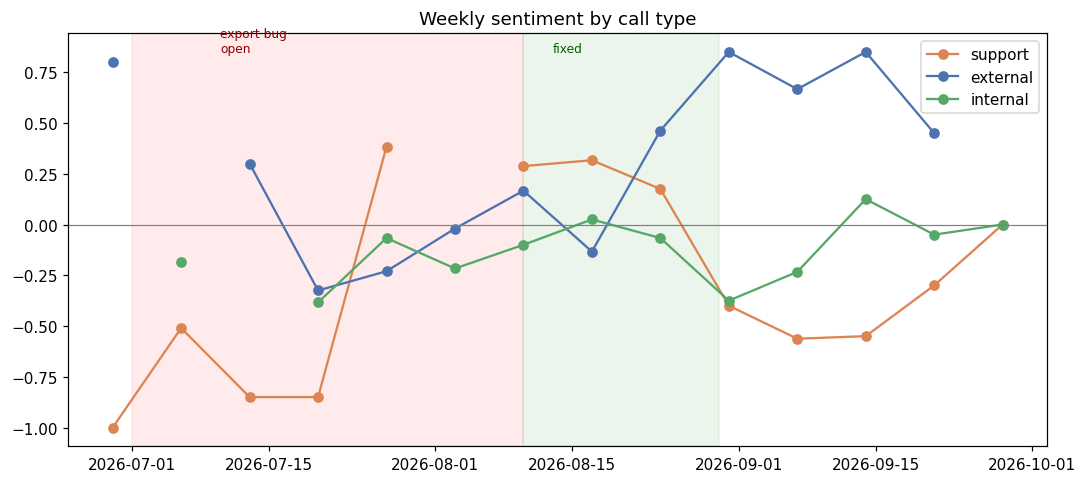

In [11]:
df["week"] = df["date"].dt.to_period("W").apply(lambda p: p.start_time)
weekly = df.groupby(["week", "call_type"])["sentiment_score"].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 4.5))
for ct, color in zip(["support", "external", "internal"], ["#DD8452", "#4C72B0", "#55A868"]):
    ax.plot(weekly.index, weekly[ct], marker="o", label=ct, color=color)
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvspan(pd.Timestamp("2026-07-01"), pd.Timestamp("2026-08-10"), alpha=0.08, color="red")
ax.text(pd.Timestamp("2026-07-10"), 0.85, "export bug\nopen", fontsize=8, color="darkred")
ax.axvspan(pd.Timestamp("2026-08-10"), pd.Timestamp("2026-08-30"), alpha=0.08, color="green")
ax.text(pd.Timestamp("2026-08-13"), 0.85, "fixed", fontsize=8, color="darkgreen")
ax.set_title("Weekly sentiment by call type")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_sentiment_trend.png", bbox_inches="tight")
plt.show()

**Reading this honestly:** support sentiment tracks the bug cleanly through the "open"
window — sharp dip, recovery right as the fix ships. But it dips *again* in late August/
September, well after the bug was confirmed fixed. That's not a relapse: checking the
underlying calls shows it's a coincidental cluster of unrelated complaints (login/SSO,
performance, billing) landing in the same few weeks — not a resurgence of the export issue.
This is the actual reason **call-type-level sentiment isn't the right unit for diagnosis** —
it tells you something is off, but not what. You need the topic-level view (§2, §4.2) to
tell a real signal (one recurring, fixable issue) apart from unrelated noise that happens
to land in the same week. We're calling this out explicitly rather than cropping the chart
to hide it — a dashboard that only ever shows clean stories isn't trustworthy.

### 3.2 Zooming in on the export-bug narrative specifically

This is the clearest trend in the dataset: a single bug's sentiment arc, visible across
all three call types, in the order you'd expect a real incident to unfold.

In [12]:
export_related = df[df["synthetic_topic_label"].str.contains("export")].sort_values("date")
export_related[["date", "call_type", "synthetic_topic_label", "sentiment_score"]]

,date,call_type,synthetic_topic_label,sentiment_score
1,2026-07-04,support,export_bug,-1.00
5,2026-07-09,support,export_bug,-0.85
6,2026-07-09,internal,bug_triage_export_early,-0.45
7,2026-07-10,support,export_bug,-1.00
9,2026-07-11,support,export_bug,-0.85
11,2026-07-17,support,export_bug,-1.00
12,2026-07-18,support,export_bug,-0.70
13,2026-07-20,support,export_bug,-0.85
14,2026-07-21,internal,cross_team_escalation_export,-0.25
16,2026-07-23,internal,bug_triage_export_escalation,-0.65


Reading the sequence: the bug is first reported by customers (support, **-0.7 to -1.0**)
starting 2026-07-04. Engineering acknowledges it internally 5 days later but it sits in
backlog. It only gets pulled forward after a customer explicitly ties it to renewal risk
(external, **-0.85**) on 2026-07-29 — **25 days after the first customer complaint**.
The fix ships 2026-08-10, and support sentiment flips to **+0.75 to +0.90** within days.
That lag is bonus insight #1, below.

## 4. Beyond the required tasks: what else this data can tell you

Three of these are implemented with code below; two are described with reasoning but
not implemented, per the assignment's own guidance that a well-articulated idea is more
valuable than a half-built one.

### 4.1 [Implemented] Cross-channel signal lag — how long did it take to notice and fix?

**Who cares:** engineering leads and product managers. If the same issue is visible in
support tickets weeks before it reaches a sprint board, that's a process gap, not a
staffing gap — worth knowing before throwing headcount at "we're too slow to ship fixes."

In [13]:
milestones = {
    "First customer complaint (support)": "export_bug",
    "First internal awareness (eng triage)": "bug_triage_export_early",
    "Escalated internally (pulled forward)": "bug_triage_export_escalation",
    "First tied to renewal risk (external)": "renewal_risk_export_bug",
    "Fix shipped (internal)": "bug_triage_export_shipped",
    "Customer confirms resolved (support)": "export_bug_resolved",
}
timeline = pd.Series({k: df[df["synthetic_topic_label"] == v]["date"].min() for k, v in milestones.items()}).sort_values()
lags = timeline.diff().dt.days.fillna(0).astype(int)
for (label, date), lag in zip(timeline.items(), lags):
    print(f"{date.date()}  (+{lag:2d}d)  {label}")

print(f"\nTotal: {(timeline.iloc[-1] - timeline.iloc[0]).days} days from first customer complaint to confirmed resolution.")
print(f"{(timeline['Escalated internally (pulled forward)'] - timeline['First customer complaint (support)']).days} days "
      f"elapsed before the issue was treated as urgent internally — by which point it had already surfaced 3 separate times in support.")

2026-07-04  (+ 0d)  First customer complaint (support)
2026-07-09  (+ 5d)  First internal awareness (eng triage)
2026-07-23  (+14d)  Escalated internally (pulled forward)
2026-07-29  (+ 6d)  First tied to renewal risk (external)
2026-08-10  (+12d)  Fix shipped (internal)
2026-08-16  (+ 6d)  Customer confirms resolved (support)

Total: 43 days from first customer complaint to confirmed resolution.
19 days elapsed before the issue was treated as urgent internally — by which point it had already surfaced 3 separate times in support.


**Recommendation:** surface a simple "this topic has appeared in N support calls in the
last 30 days" counter directly on the engineering backlog, instead of relying on someone
noticing the pattern by memory. The internal roadmap-planning call in this dataset
independently arrives at the same conclusion ("support tickets and account escalations
aren't visible to engineering in one place") — see cluster #6.

### 4.2 [Implemented] Volume × negativity: where should engineering/support focus first?

**Who cares:** support leaders and engineering leads prioritizing a backlog. A topic that's
both common *and* negative is a better use of a sprint than a topic that's rare but severe,
or common but merely neutral.

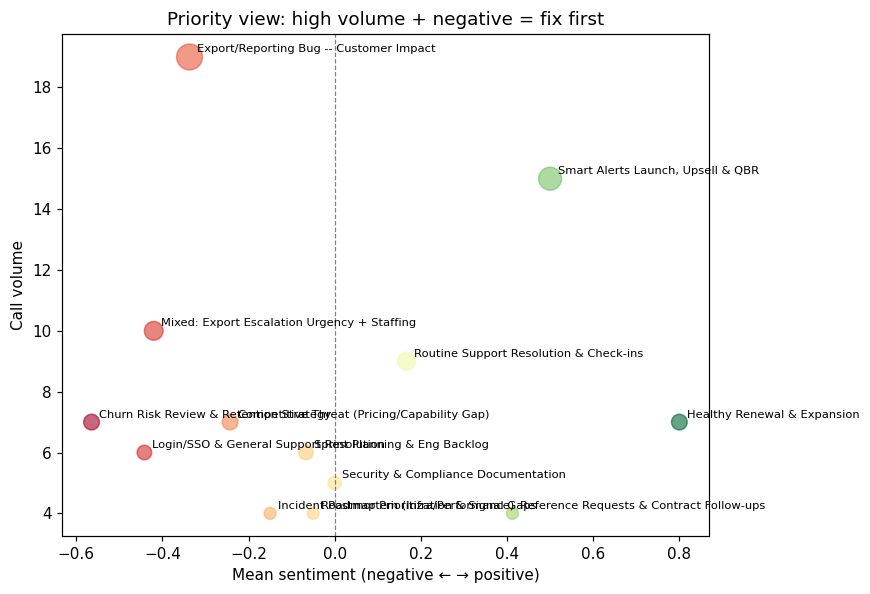

,category,n,mean_sentiment,priority_score
2,Export/Reporting Bug -- Customer Impact,19,-0.34,6.40
6,Mixed: Export Escalation Urgency + Staffing,10,-0.42,4.20
0,Churn Risk Review & Retention Strategy,7,-0.56,3.95
5,Login/SSO & General Support Resolution,6,-0.44,2.65
1,Competitive Threat (Pricing/Capability Gap),7,-0.24,1.70
4,Incident Postmortem (Infra/Performance),4,-0.15,0.60
12,Sprint Planning & Eng Backlog,6,-0.07,0.40
8,Roadmap Prioritization & Signal Gaps,4,-0.05,0.20
3,Healthy Renewal & Expansion,7,0.80,-0.00
7,Reference Requests & Contract Follow-ups,4,0.41,-0.00


In [14]:
priority = df.groupby("category").agg(n=("call_id", "count"), mean_sentiment=("sentiment_score", "mean")).reset_index()
priority["priority_score"] = priority["n"] * -priority["mean_sentiment"].clip(upper=0)
priority = priority.sort_values("priority_score", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(priority["mean_sentiment"], priority["n"], s=priority["n"] * 15, alpha=0.6, c=priority["mean_sentiment"], cmap="RdYlGn")
for _, r in priority.iterrows():
    ax.annotate(r["category"], (r["mean_sentiment"], r["n"]), fontsize=7.5, xytext=(5, 3), textcoords="offset points")
ax.axvline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_xlabel("Mean sentiment (negative ← → positive)")
ax.set_ylabel("Call volume")
ax.set_title("Priority view: high volume + negative = fix first")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_priority_matrix.png", bbox_inches="tight")
plt.show()

priority[["category", "n", "mean_sentiment", "priority_score"]].round(2)

The export/reporting bug category is both the single highest-volume topic in the entire
dataset *and* solidly negative — it's the clear #1 by this ranking, which matches what we
already found by reading the transcripts in §2.4 and §3.2. Having a second, independent
method agree with the qualitative read is a useful sanity check before taking it to
leadership.

### 4.3 [Implemented] Sentiment score ≠ churn risk — these need to be tracked separately

**Who cares:** sales/CS leaders building a churn-risk dashboard. If you build "flag
negative-sentiment calls" as your churn radar, you will miss the quietest, most dangerous
signal: a customer who calmly mentions they're evaluating a competitor.

In [15]:
import re

RISK_PHRASES = ["evaluating", "considering not renewing", "competitor", "lumina",
                 "other tools", "other vendors", "won't renew", "not renew", "alternative"]
risk_re = [re.compile(p) for p in RISK_PHRASES]
df["churn_risk_flag"] = df["scored_text"].str.lower().apply(lambda t: any(r.search(t) for r in risk_re))

print(pd.crosstab(df["churn_risk_flag"], df["sentiment_label"], margins=True))
print()
flagged_not_negative = df[df["churn_risk_flag"] & (df["sentiment_label"] != "negative")]
print(f"{len(flagged_not_negative)} of {df['churn_risk_flag'].sum()} keyword-flagged 'risk' calls are NOT scored negative sentiment:")
print(flagged_not_negative[["call_id", "call_type", "synthetic_topic_label", "sentiment_label"]].to_string(index=False))

sentiment_label  negative  neutral  positive  All
churn_risk_flag                                  
False                  39       20        29   88
True                    9        3         3   15
All                    48       23        32  103

6 of 15 keyword-flagged 'risk' calls are NOT scored negative sentiment:
  call_id call_type        synthetic_topic_label sentiment_label
CALL-0035  internal         competitive_strategy         neutral
CALL-0038  internal         competitive_strategy         neutral
CALL-0041  internal         competitive_strategy         neutral
CALL-0072  internal launch_planning_smart_alerts        positive
CALL-0076  internal launch_planning_smart_alerts        positive
CALL-0095  internal launch_planning_smart_alerts        positive


Two things are true at once here, and both matter:

1. **Sentiment alone misses risk.** A customer calmly evaluating "Lumina Analytics" on
   price scores only mildly negative (-0.35) — far milder than an angry support call about
   a solved bug. A sentiment-only alert would under-rank the more dangerous signal.
2. **Naive keyword risk-flagging over-fires.** 6 of the 15 keyword-flagged calls are
   internal teams calmly discussing competitive *strategy* or a feature *launch* that
   happens to mention a competitor by name — not customer-expressed risk at all. This is
   the same lesson as sentiment: a keyword match isn't contextual judgment. In production,
   "is this call a churn risk" deserves its own LLM-judged classification, separate from
   sentiment, rather than either a sentiment threshold or a keyword list.

### 4.4 [Described, not implemented] Account-level health rollup

**Idea:** aggregate category + sentiment + recency *per customer account* across all
their calls (support + external + any internal mentions) into a single rolling health
score, refreshed after every call.

**Who'd use it:** account managers and CS leaders, ahead of a renewal or QBR — instead of
reading through transcripts to remember "has this account had problems lately," they'd see
a trend line per account: sentiment over the last 90 days, open issue categories, and a
flag if the account has touched more than one negative category recently (a compounding-risk
signal that no single call would reveal on its own).

**Why not implemented here:** this dataset's synthetic customer names are assigned
randomly per call rather than tracking a consistent fictional account over time (see
`data/README.md`), so a real account-level rollup would currently aggregate noise, not
signal. Fixing that requires regenerating the dataset with persistent per-account identity
across calls — straightforward, but a data change we'd want sign-off on before doing, since
it reshapes the whole generator. Flagging it here as the most natural "next" feature rather
than quietly building it on top of data that can't really support it yet.

### 4.5 [Described, not implemented] Auto-generated pre-call briefings

**Idea:** before any call with an account (a QBR, a renewal, even a routine support call),
auto-generate a one-paragraph briefing: what's come up across *all* channels for this
account recently — support tickets, prior AM conversations, any internal escalations tied
to them — so the person on the call isn't caught off guard.

**Who'd use it:** account managers walking into a renewal call cold; support agents who
don't have visibility into whether an account is already a flagged churn risk; engineering
leads deciding whether a bug fix needs to be expedited because it's about to come up in a
renewal conversation.

**Why it matters beyond convenience:** this directly targets the process gap this dataset's
own internal roadmap-planning call identifies — "support tickets and account escalations
aren't visible to engineering in one place," which is also exactly why the export bug took
25 days to get escalated (§4.1). A pre-call briefing is the human-facing version of the same
fix: make cross-channel signal visible by default instead of requiring someone to notice it.

**Why not implemented here:** this is a generation task (LLM summarization over a
retrieved, per-account slice of transcripts), not an analysis task — it's a thin layer on
top of the account rollup in §4.4, so it has the same dependency (persistent account
identity in the data) and is a natural "phase 2" once that's in place.

## 5. Summary for leadership

- **Categorization:** 13 data-driven categories recovered from 103 calls via embeddings +
  clustering, validated at ~76% purity against known-synthetic ground truth. One category —
  the export/reporting bug — is the only one with meaningful presence in all three call
  types, and is also the single highest-volume category overall.
- **Sentiment:** off-the-shelf tools (VADER, DistilBERT) are unreliable on polite-but-
  frustrated B2B dialogue; a contextual, LLM-style approach is necessary, not optional, for
  this domain. Support skews more negative than external/internal by design (it's the
  reactive channel) — but the *topic* driving that, not the channel itself, is what's
  actionable.
- **The throughline finding:** the export bug took 25 days to be treated as urgent
  internally after the first customer complaint, and 37 days to ship a fix — fully visible
  in the data the moment you look across channels instead of within just one.
- **Bonus insights:** two implemented analyses (priority matrix, churn-risk-vs-sentiment)
  plus two described-but-not-built ideas (account health rollup, auto-briefings) that both
  point at the same underlying gap: cross-channel visibility.

In [16]:
df.to_csv(f"{OUT_DIR}/scored_transcripts.csv", index=False)
priority.to_csv(f"{OUT_DIR}/category_priority.csv", index=False)
print("Saved outputs/data/scored_transcripts.csv and outputs/data/category_priority.csv")

Saved outputs/data/scored_transcripts.csv and outputs/data/category_priority.csv
